# Scratch: stable manifold and exact pre-images of the 2-qubit protocol

Exploratory notebook, moved here from the repository root, where it was `test.ipynb`. No data file or figure depends on it.
- Computes the same stable-manifold series and 400-round iteration as `stable_manifold.ipynb`, without saving.
- Checks that some pure inputs reach $|T^\star\rangle$ exactly after a few rounds.
- Builds the set of pure inputs that first reach the target after $N$ successful rounds by inverting the Bloch map (at arbitrary precision), and plots them on the Bloch sphere.

In [1]:
from qiskit import __version__
print(__version__)

2.4.2


In [2]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector, state_fidelity, Pauli, DensityMatrix, partial_trace
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from qiskit_aer.library import SaveDensityMatrix, SaveStatevector, SetDensityMatrix
from qiskit import transpile 
import numpy as np
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError
from qiskit.circuit.library import HGate, UnitaryGate, IGate
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, NullFormatter
from matplotlib.gridspec import GridSpec
from scipy.optimize import curve_fit
from mpmath import mp

In [3]:
def inf_to_error(infidelity_list, num_qubits):
    error_rates_list = []
    dimension = 2**num_qubits
    for infidelity in infidelity_list:
        error_rates_list.append( infidelity * (dimension / (dimension - 1)) )
    
    return error_rates_list

# Taylor expanding to 120th term for a mixed input state

In [6]:
mp.dps = 100

# Fixed point
zstar = mp.findroot(
    lambda z: z**3 + z**2 + z - 1,
    (mp.mpf("0.5"), mp.mpf("0.6"))
)
xstar = mp.sqrt(1 - zstar**2)

lam = xstar
q0 = 1 + zstar**2

# Taylor expansion order
N = 120

# X(t) = sum a[n]*t**n
# Z(t) = sum b[n]*t**n
# Q(t) = 1 + Z(t)**2 = sum q[n]*t**n
a = [mp.mpf(0)] * (N + 1)
b = [mp.mpf(0)] * (N + 1)
q = [mp.mpf(0)] * (N + 1)

a[0], b[0] = xstar, zstar
a[1] = b[1] = mp.mpf(1)

q[0] = q0
q[1] = 2 * zstar

# Recursively determine coefficients
for n in range(2, N + 1):

    bb = mp.fsum(
        b[k] * b[n-k] for k in range(1, n)
    )
    aa = mp.fsum(
        a[k] * a[n-k] for k in range(1, n)
    )
    qx = mp.fsum(
        q[k] * lam**(n-k) * a[n-k]
        for k in range(1, n)
    )
    qz = mp.fsum(
        q[k] * lam**(n-k) * b[n-k]
        for k in range(1, n)
    )

    A = mp.matrix([
        [q0 * lam**n, 2*xstar*zstar - 2],
        [-2*xstar, q0*lam**n + 2*zstar**2]
    ])

    rhs = mp.matrix([
        -xstar*bb - qx,
        aa - zstar*bb - qz
    ])

    result = mp.lu_solve(A, rhs)

    a[n] = result[0]
    b[n] = result[1]

    q[n] = 2*zstar*b[n] + bb

# Evaluate the stable manifold
t = mp.mpf("-0.02")

x_in = mp.fsum(a[n]*t**n for n in range(N+1))
z_in = mp.fsum(b[n]*t**n for n in range(N+1))

print("x_in =", mp.nstr(x_in, 30))
print("z_in =", mp.nstr(z_in, 30))

# Verify physicality
r_squared = x_in**2 + z_in**2

print("|r|^2 =", mp.nstr(r_squared, 30))

x_in = 0.821680873558761730519437953156
z_in = 0.526236101185028884090535408586
|r|^2 = 0.952083892162709740483223969911


In [11]:
x = mp.mpf(x_in)
z = mp.mpf(z_in)

rounds = 400

infidelity_list = []
success_probabilities = []

def infidelity(x, z):
    return (1 - xstar*x - zstar*z) / 2

infidelity_list.append(infidelity(x, z))

for r in range(rounds):
    denom = 1 + z**2

    p_success = denom / 2

    x_new = 2*z / denom
    z_new = x**2 / denom

    x, z = x_new, z_new

    success_probabilities.append(p_success)
    infidelity_list.append(infidelity(x, z))

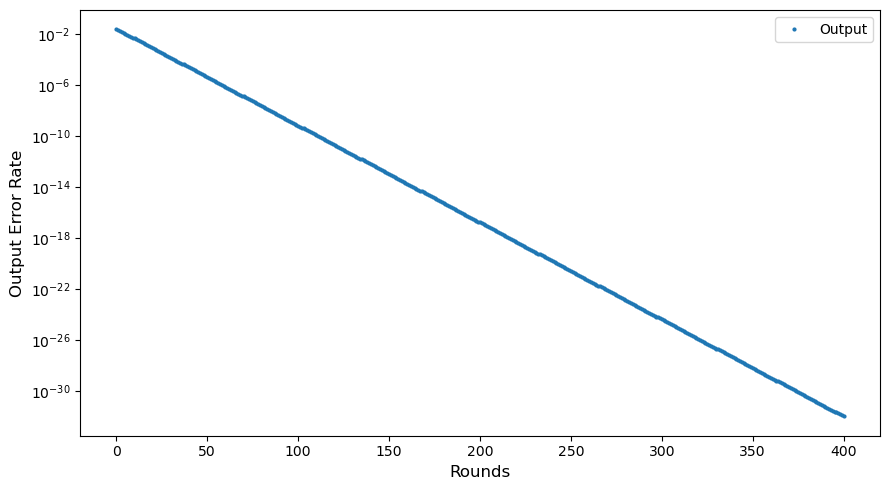

In [15]:
from matplotlib.ticker import LogLocator, LogFormatterMathtext
rounds_arr = np.arange(rounds + 1)

# Convert mpmath values to float for plotting
output_error_rate = np.array([
    float(2 * inf)
    for inf in infidelity_list
])

plt.figure(figsize=(9, 5))

plt.plot(rounds_arr, output_error_rate, 'o',
         markersize=2, label='Output')

plt.xlabel("Rounds", fontsize=12)
plt.ylabel("Output Error Rate", fontsize=12)

# Logarithmic y-axis
plt.yscale('log')

ax = plt.gca()

# Display ticks as 10^{-3}, 10^{-4}, etc.
ax.yaxis.set_major_locator(LogLocator(base=10))
ax.yaxis.set_major_formatter(LogFormatterMathtext(base=10))

plt.legend()
plt.tight_layout()
plt.show()

# For rounds = 4, pure input converge to target exactly

In [39]:
# Target magic state
mp.dps = 100

zstar = mp.findroot(
    lambda z: z**3 + z**2 + z - 1,
    (mp.mpf("0.5"), mp.mpf("0.6"))
)
xstar = mp.sqrt(1 - zstar**2)
theta = float(mp.atan2(xstar, zstar))

ideal = QuantumCircuit(1)
ideal.ry(theta, 0)
ideal_dm = DensityMatrix(ideal)

# Pauli matrices
I = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)


w = mp.exp(-1j * theta / 2)

# Construct normalized statevector
psi = np.array([1, complex(w)], dtype=complex)
psi = psi / np.linalg.norm(psi)

# Convert to density matrix
rho_in = DensityMatrix(Statevector(psi))

rounds = 6
infidelity_list = [
    1 - state_fidelity(ideal_dm, rho_in)
]
success_probabilities = []

backend = AerSimulator(method="density_matrix")

for r in range(rounds):

    # Two independent copies
    rho_two = DensityMatrix(
        np.kron(rho_in.data, rho_in.data)
    )

    circuit = QuantumCircuit(2)
    circuit.append(SetDensityMatrix(rho_two), circuit.qubits)

    # Distillation protocol
    circuit.cx(0, 1)
    circuit.h(0)

    # Save the state before postselection
    circuit.append(
        SaveDensityMatrix(
            num_qubits=2,
            label="pre_measure"
        ),
        circuit.qubits
    )

    result = backend.run(circuit, shots=1).result()
    rho_pre = np.asarray(
        result.data(0)["pre_measure"].data
    )

    # Project onto measurement outcome q1 = 0.
    # In Qiskit's little-endian convention,
    # the corresponding basis indices are 0 and 1.
    accepted = rho_pre[np.ix_([0, 1], [0, 1])]

    p_success = float(np.trace(accepted).real)
    success_probabilities.append(p_success)

    # Normalize the accepted one-qubit state
    rho_out = DensityMatrix(accepted / p_success)

    infidelity = 1 - state_fidelity(ideal_dm, rho_out)
    infidelity_list.append(infidelity)

    # Feed accepted state into the next round
    rho_in = rho_out


In [40]:
print(infidelity_list)

[0.13132364711983613, 0.3522011287389578, 0.2955977425220847, 0.7044022574779152, 4.440892098500626e-16, -4.440892098500626e-16, -4.440892098500626e-16]


# Displaying on a Bloch sphere

N = 3
Expected number = 4
Maximum round-N Bloch-vector error = 7.1436712e-101


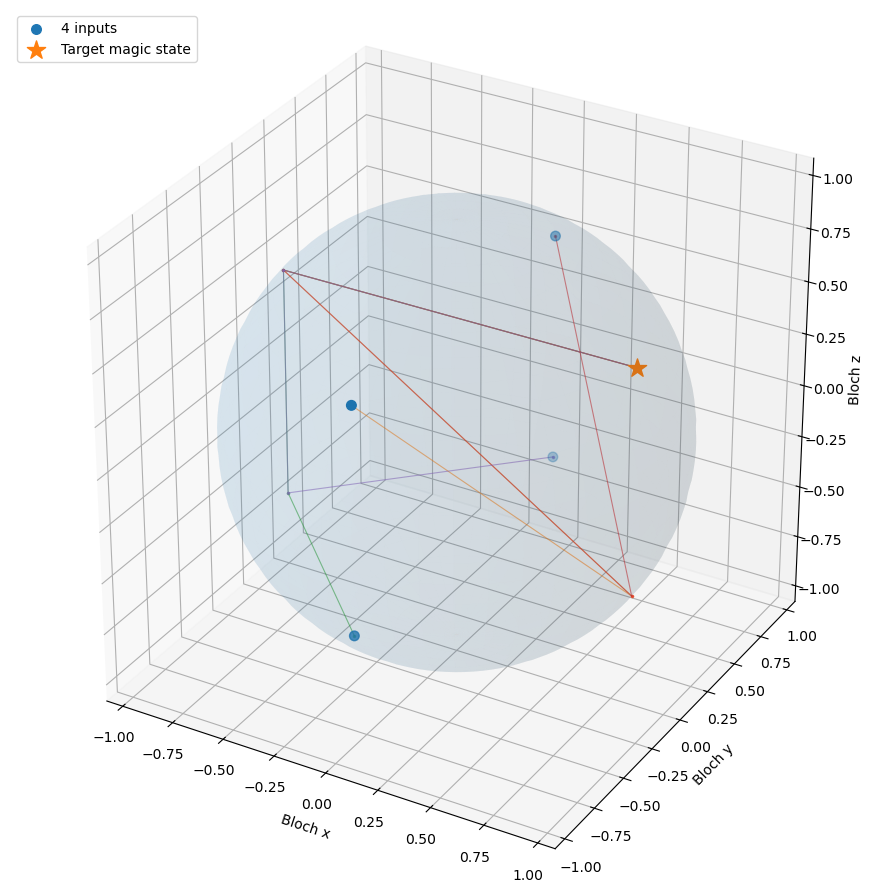

In [50]:
# Choose the number of successful distillation rounds (1 <= N <= 5).
N = 3

if not isinstance(N, int) or not 1 <= N <= 5:
    raise ValueError("Choose an integer N between 1 and 5.")

# Arbitrary precision for the algebraic target and inverse-branch construction.
mp.dps = 100
tolerance = mp.mpf("1e-80")


def real_cuberoot(x):
    # Real cube root, including for negative real arguments 
    x = mp.mpf(x)
    return mp.sign(x) * mp.power(abs(x), mp.mpf(1) / 3)


def distillation_map(w):
    # One successful round in the pure-state amplitude-ratio representation 
    return (1 - w**2) / (1 + w**2)


def inverse_branches(v):
    # The two inverse branches satisfying distillation_map(w) = v 
    root = mp.sqrt((1 - v) / (1 + v))
    return root, -root


def remove_numerical_duplicates(values, tol):
    # Remove duplicate complex values while preserving their order 
    unique = []
    for value in values:
        if not any(abs(value - previous) < tol for previous in unique):
            unique.append(value)
    return unique


def bloch_coordinates(w):
    # Convert amplitude ratio w into pure-state Bloch coordinates 
    denominator = 1 + abs(w)**2
    return (
        2 * mp.re(w) / denominator,
        2 * mp.im(w) / denominator,
        (1 - abs(w)**2) / denominator,
    )


def forward_trajectory(w, rounds):
    # Return amplitude ratios from the input through the requested rounds 
    trajectory = [w]
    for _ in range(rounds):
        trajectory.append(distillation_map(trajectory[-1]))
    return trajectory


# Evaluate the closed-form algebraic expression for z_star.
z_star = (
    real_cuberoot(17 + 3 * mp.sqrt(33))
    + real_cuberoot(17 - 3 * mp.sqrt(33))
    - 1
) / 3
x_star = mp.sqrt(1 - z_star**2)
w_star = mp.mpc(z_star, 0)

target_bloch = (x_star, mp.mpf(0), z_star)

# Build P_n = {w : f^n(w) = w_star}.
# The first-arrival inputs at round N are P_N \ P_(N-1).
levels = [[w_star]]

for _ in range(1, N + 1):
    candidates = []
    for output_ratio in levels[-1]:
        candidates.extend(inverse_branches(output_ratio))
    levels.append(remove_numerical_duplicates(candidates, tolerance))

previous_level = levels[N - 1]
current_level = levels[N]

inputs = [
    w for w in current_level
    if not any(abs(w - old) < tolerance for old in previous_level)
]

expected_inputs = 2**(N - 1)
if len(inputs) != expected_inputs:
    raise RuntimeError(
        f"Found {len(inputs)} first-arrival inputs; "
        f"expected {expected_inputs}. Increase mp.mp.dps if needed."
    )

# Stable ordering for reproducible plots.
inputs.sort(key=lambda w: (float(mp.arg(w)), float(abs(w))))

# Verify that every selected input reaches the target after N rounds.
errors = []
for w in inputs:
    final_ratio = forward_trajectory(w, N)[-1]
    final_bloch = bloch_coordinates(final_ratio)
    error = mp.sqrt(
        sum((final_bloch[i] - target_bloch[i])**2 for i in range(3))
    )
    errors.append(error)

print(f"N = {N}")
print(f"Expected number = {expected_inputs}")
print("Maximum round-N Bloch-vector error =", mp.nstr(max(errors), 8))

# Matplotlib uses ordinary floating-point coordinates for rendering only.
def to_float_bloch(w):
    return np.asarray([float(value) for value in bloch_coordinates(w)])

target = np.asarray([float(value) for value in target_bloch])
input_points = np.asarray([to_float_bloch(w) for w in inputs])

fig = plt.figure(figsize=(10, 9))
ax = fig.add_subplot(111, projection="3d")

# Draw the unit Bloch sphere.
u = np.linspace(0, 2 * np.pi, 90)
v = np.linspace(0, np.pi, 60)
sx = np.outer(np.cos(u), np.sin(v))
sy = np.outer(np.sin(u), np.sin(v))
sz = np.outer(np.ones_like(u), np.cos(v))
ax.plot_surface(sx, sy, sz, alpha=0.08, linewidth=0)

# Plot each input and its discrete sequence of successful outputs.
for w in inputs:
    ratios = forward_trajectory(w, N)
    points = np.asarray([to_float_bloch(value) for value in ratios])
    ax.plot(
        points[:, 0], points[:, 1], points[:, 2],
        marker=".", markersize=3, linewidth=0.8, alpha=0.55
    )

ax.scatter(
    input_points[:, 0], input_points[:, 1], input_points[:, 2],
    s=48, marker="o",
    label=f"{len(inputs)} inputs"
)
ax.scatter(
    [target[0]], [target[1]], [target[2]],
    s=190, marker="*", label="Target magic state"
)


ax.set_xlabel("Bloch x")
ax.set_ylabel("Bloch y")
ax.set_zlabel("Bloch z")
ax.set_xlim(-1.08, 1.08)
ax.set_ylim(-1.08, 1.08)
ax.set_zlim(-1.08, 1.08)
ax.set_box_aspect((1, 1, 1))
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()
